### 0. Google-Drive mount (skip on local Jupyter)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

ROOT_PATH = "/content/drive/MyDrive/Graduation Thesis/fl_localize_stitch_vit/"
# ROOT_PATH = "/content/drive/Othercomputers/Victus/Disk D/New Uzb Semester 8/Graduation Thesis/fl_localize_stitch_vit/"
# ROOT_PATH = "./"              # to run locally

Mounted at /content/drive


#### 0a. Dependencies

In [2]:
import subprocess, sys, importlib, pathlib, os

# Restart the runtime before rerunning with these CUDA settings.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # configures deterministic cuBLAS workspace memory for reproducible GPU computations.

PKGS = ["torch", "torchvision", "timm", "tqdm", "pandas", "seaborn"]
for pkg in PKGS:
    try:
        importlib.import_module(pkg)
    except ModuleNotFoundError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg])

In [3]:
ROOT_PATH = pathlib.Path(ROOT_PATH).resolve()
sys.path.extend([str(ROOT_PATH)])

ckpt_dir = ROOT_PATH / "checkpoints"
ckpt_dir.mkdir(exist_ok=True)

### 1. Hyper-parameters & torchvision transforms  

In [95]:
NUM_CLIENTS = 5
BACKBONE_NAME = "vit_small_patch16_224"  # ~22 M parameters
BATCH_SIZE  = 64
IMG_SIZE    = 224    # ViT default patch‑16 grid
ALPHA       = 0.1    # Dirichlet concentration → stronger skew < 1, weaker skew > 1
SUBSET_FRAC = 0.5
DATASET     = "DTD"
SEED        = 46
LOAD_CHECKPOINTS = False  # Keep False for independent seed runs

FEDADAM_LR    = 1e-2  # Server learning rate; tune using validation data
FEDADAM_BETA1 = 0.9
FEDADAM_BETA2 = 0.99
FEDADAM_TAU   = 1e-3

import timm
from torchvision import transforms

pretrained_cfg = timm.get_pretrained_cfg(BACKBONE_NAME)

preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    # transforms.Lambda(lambda x: x.expand(3, -1, -1)),        # 1-→3 channels          # DTD is already 3-channel (3, H, W).
    transforms.Normalize(pretrained_cfg.mean, pretrained_cfg.std),
])

### 2. Data loading (with sub-sampling) & skewed client splits

In [96]:
from torch.utils.data import DataLoader, Subset
import torch, numpy as np
import random

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(SEED)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

DATA_ROOT = "./data"
def make_dataset(name, subset_frac=SUBSET_FRAC, seed=SEED):
    if name == "EuroSAT":
        from torchvision.datasets import EuroSAT
        # Load the full dataset once
        full_dataset = EuroSAT(DATA_ROOT, transform=preprocess, download=True)
        # Split into 80% train / 20% test
        train_size = int(0.8 * len(full_dataset))
        test_size  = len(full_dataset) - train_size
        train, test = torch.utils.data.random_split(full_dataset, [train_size, test_size])

    elif name == "DTD":
        from torchvision.datasets import DTD
        train = DTD(DATA_ROOT, split="train", partition=1,        download=True, transform=preprocess)
        val   = DTD(DATA_ROOT, split="val", partition=1,          download=True, transform=preprocess)
        test  = DTD(DATA_ROOT, split="test", partition=1,         download=True, transform=preprocess)

    # elif name == "RESISC45":
    #     from torchvision.datasets import RESISC45
    #     train = RESISC45(DATA_ROOT, split="train",   download=True, transform=preprocess)
    #     test  = RESISC45(DATA_ROOT, split="test",    download=False, transform=preprocess)

    elif name == "StanfordCars":
        from torchvision.datasets import StanfordCars
        train = StanfordCars(DATA_ROOT, split="train",       download=True, transform=preprocess)
        test  = StanfordCars(DATA_ROOT, split="test",        download=True, transform=preprocess)

    else:
        raise ValueError("Unknown dataset")

    if name != "DTD":
        val_size = max(1, len(train) // 5)
        train, val = torch.utils.data.random_split(
            train, [len(train) - val_size, val_size],
            generator=torch.Generator().manual_seed(seed))

    return train, val, test


# Dirichlet split
def create_skewed_clients(dataset, num_clients=NUM_CLIENTS, alpha=ALPHA, seed=SEED):
    """
    Returns:
        clients_indices: list of lists of indices for each client
        num_classes: number of classes in the dataset
    """
    rng = np.random.default_rng(seed)

    if hasattr(dataset, "targets"):
        labels = np.array(dataset.targets)
    else:
        labels = np.array([y for _, y in dataset])

    classes = np.unique(labels)
    class_indices = [np.where(labels == c)[0] for c in classes]
    clients = [[] for _ in range(num_clients)]
    for class_i in class_indices:
        rng.shuffle(class_i)
        parts = rng.dirichlet(alpha * np.ones(num_clients))
        splits = (np.cumsum(parts) * len(class_i)).astype(int)[:-1]
        for cli, chunk in zip(clients, np.split(class_i, splits)):
            cli.extend(chunk)
    return clients, len(classes)


train_ds, val_ds, test_ds = make_dataset(DATASET)

client_indices, NUM_CLASSES = create_skewed_clients(train_ds)
make_loader = lambda subset, seed: DataLoader(
    subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    generator=torch.Generator().manual_seed(seed)
)
train_loaders = [make_loader(Subset(train_ds, idx), SEED + NUM_CLIENTS + cid) for cid, idx in enumerate(client_indices)]
client_sizes = [len(loader.dataset) for loader in train_loaders]   # for weighted FedAvg

val_loader    = DataLoader(val_ds, batch_size=256, shuffle=False,
                            num_workers=2, pin_memory=True,
                            generator=torch.Generator().manual_seed(SEED))

test_loader   = DataLoader(test_ds, batch_size=256, shuffle=False,
                            num_workers=2, pin_memory=True,
                            generator=torch.Generator().manual_seed(SEED))

print(f"{DATASET}: {len(train_ds):5d} train   {len(val_ds):5d} val   {len(test_ds):5d} test   {NUM_CLASSES} classes")

DTD:  1880 train    1880 val    1880 test   47 classes


### 3. ViT-Small/16 model

In [97]:
import copy
import timm, torch.nn as nn

def make_classifier(num_classes: int = NUM_CLASSES):
    model = timm.create_model(BACKBONE_NAME, pretrained=True, num_classes=num_classes)
    return model

seed_everything(SEED)
pretrained_model = make_classifier().cpu().eval()

### 4. Train Clients

In [98]:
from torch.optim import AdamW
from torch.nn.functional import cross_entropy
from tqdm import tqdm

def train_model(model, loader, client_id, epochs=1, device="cuda", seed=None):
    if seed is not None:
        seed_everything(seed)
        if loader.generator is not None:
            loader.generator.manual_seed(seed)
    model.to(device)

    opt = AdamW(model.parameters(), lr=3e-4)
    scaler = torch.amp.GradScaler('cuda')

    for ep in range(1, epochs+1):
        model.train()

        pbar = tqdm(loader, desc=f"Client{client_id} Epoch{ep}")
        for x, y in pbar:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad()

            with torch.amp.autocast('cuda'):
                out = model(x)
                loss = cross_entropy(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()

        # Checkpoint
        # torch.save(model.state_dict(), ckpt_dir / f"client{client_id}_epoch{ep}.pt")

    return model.cpu().eval()          # leave in eval mode!

In [99]:
# Train all clients
if not LOAD_CHECKPOINTS:
    client_models = []
    for cid, ld in enumerate(train_loaders):
        client_models.append(train_model(copy.deepcopy(pretrained_model), ld, cid, seed=SEED + NUM_CLIENTS + cid))

Client4 Epoch1: 100%|██████████| 5/5 [00:02<00:00,  1.79it/s]


#### Or load weights (state dict) from a checkpoint:

In [100]:
if LOAD_CHECKPOINTS:
    client_models = []
    ckpt_dir = pathlib.Path(ROOT_PATH) / "checkpoints"

    for cid in range(NUM_CLIENTS):
        model = timm.create_model(BACKBONE_NAME, num_classes=NUM_CLASSES)

        client_ckpt = f"client{cid}_epoch1.pt"
        state = torch.load(ckpt_dir / client_ckpt, map_location="cpu")

        model.load_state_dict(state, strict=True)
        client_models.append(model.eval())

#### 4a. Evaluate clients separately

Evaluate the clients trained on **imbalanced data** using the held-out validation split:

In [101]:
def accuracy(model, loader):
    model.eval().cuda()
    preds, labels = [], []

    with torch.no_grad():
        for x, y in loader:
            preds.extend(model(x.cuda()).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    model.cpu()
    return (np.array(preds) == np.array(labels)).mean()

In [102]:
import copy

print("Client validation accuracies:")

for cid, (clmodel, ld) in enumerate(zip(client_models, train_loaders)):
    acc   = accuracy(clmodel, val_loader)
    print(f"  client{cid}:  {acc:.4f}")

Client validation accuracies:
  client0:  0.2261
  client1:  0.1287
  client2:  0.1601
  client3:  0.2027
  client4:  0.1654


In [103]:
print("Client initial train dataset sizes:")

for i, ld in enumerate(train_loaders):
    print(f"  client{i}:  {len(ld.dataset)}")

Client initial train dataset sizes:
  client0:  474
  client1:  331
  client2:  368
  client3:  392
  client4:  315


### 5. Localizer

In [104]:
import torch
from typing import Dict, List

class SimpleLocalizer:
    def __init__(self, pretrained: nn.Module, finetuned: nn.Module, K=0.95):
        # Task vector τ = θ_finetuned − θ_pretrained
        self.task_vector = {n: (f.detach() - p.detach())     # task vector
                      for (n, p), (_, f) in zip(pretrained.named_parameters(),
                                                finetuned.named_parameters())}

        # Global threshold for top-k magnitude
        all_vals = torch.cat([task_vector.flatten().abs() for task_vector in self.task_vector.values()])

        # add normal noise
        # all_vals = all_vals + torch.normal(mean=0, std=torch.std(all_vals) * 0.04, size=all_vals.shape)

        k = max(1, int(K * all_vals.numel()))    # max() is for safety: to choose at least one
        thresh = torch.topk(all_vals, k).values[-1]     # topk() returns namedtuple(values: List, indices: List) in decreasing order. So thresh is the minimum in the top-k or top-95% elements.

        # Masked task vector: γ ⊙ τ
        self.masks = {n: (task_vector.abs() >= thresh) for n, task_vector in self.task_vector.items()}
        self.masked_task_vector = {n: (task_vector * self.masks[n]).clone()
                                   for n, task_vector in self.task_vector.items()}

In [105]:
masked_task_vectors = []
masks = []
pretrained_copy = copy.deepcopy(pretrained_model)

for cid, clmodel in enumerate(client_models):
    print(f"Localizing client {cid}")
    localizer = SimpleLocalizer(pretrained_copy, clmodel, K=0.95)
    masked_task_vectors.append(localizer.masked_task_vector)
    masks.append(localizer.masks)

Localizing client 0
Localizing client 1
Localizing client 2
Localizing client 3
Localizing client 4


### 6. Stitch task vectors
top-K% largest magnitude weights, Yadav et al. 2023

In [106]:
import copy
def simpleStitcher(base_model: nn.Module, masked_task_vectors: List[Dict[str, torch.Tensor]],
                   masks: List[Dict[str, torch.Tensor]]):
    new_model = copy.deepcopy(base_model)
    new_model_state_dict = new_model.state_dict()

    # Average each coordinate over clients whose masks select it.
    for n in masked_task_vectors[0]:
        numerator = sum(client_masked_task_vector[n] for client_masked_task_vector in masked_task_vectors)
        denominator = torch.zeros_like(numerator)
        ## denominator += NUM_CLIENTS

        ## a = masked_task_vectors[0][n] != 0
        ## denominator += a
        ## print(denominator);break

        for mask in masks:
            denominator += mask[n].to(denominator.dtype)
        denominator.clamp_min_(1)
        new_model_state_dict[n] += numerator / denominator

    new_model.load_state_dict(new_model_state_dict, strict=True)

    return new_model.eval()

In [107]:
stitched_model = simpleStitcher(pretrained_copy, masked_task_vectors, masks)

### 7.  Baselines

#### a. Centralized Baseline Model

A single model trained on the union of all client data.

In [108]:
CENTRAL_EPOCHS = 15

if not LOAD_CHECKPOINTS:
    full_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=2, pin_memory=True,
                              generator=torch.Generator().manual_seed(SEED))

    baseline_model = train_model(copy.deepcopy(pretrained_model), full_loader, "Baseline", epochs=CENTRAL_EPOCHS, seed=SEED)

ClientBaseline Epoch15: 100%|██████████| 30/30 [00:12<00:00,  2.36it/s]


Or load from a checkpoint:

In [109]:
if LOAD_CHECKPOINTS:
    ckpt_dir = pathlib.Path(ROOT_PATH) / "checkpoints"

    baseline_model = timm.create_model(BACKBONE_NAME, num_classes=NUM_CLASSES)
    baseline_ckpt = f"centralizedBaseline_{DATASET}_epoch{CENTRAL_EPOCHS}.pt"

    state = torch.load(ckpt_dir / baseline_ckpt, map_location="cpu")
    baseline_model.load_state_dict(state, strict=True)


#### b. FedAvg (weighted by client sample counts)

In [110]:
def weight_average(models, client_sizes):
    avg = copy.deepcopy(models[0])
    total_size = sum(client_sizes)
    with torch.no_grad():
        for k in avg.state_dict().keys():
            avg.state_dict()[k].copy_(
                sum(m.state_dict()[k] * (size / total_size) for m, size in zip(models, client_sizes))
            )
    return avg

fedavg_model  = weight_average(client_models, client_sizes).eval()

#### c. FedAdam

Uses the same local AdamW training as the other methods. The server follows [Algorithm 5](https://arxiv.org/html/2003.00295v5) with sample-weighted client updates and moments retained across rounds.


In [111]:
def fedadam_update(base_model, models, client_sizes, moments=None):
    new_model = copy.deepcopy(base_model)
    averaged_model = weight_average(models, client_sizes)
    base_parameters = dict(base_model.named_parameters())
    averaged_parameters = dict(averaged_model.named_parameters())
    if moments is None:
        moments = {name: (torch.zeros_like(parameter),
                          torch.full_like(parameter, FEDADAM_TAU ** 2))
                   for name, parameter in base_parameters.items()}

    # FedAdam server update (Algorithm 5): no bias correction.
    with torch.no_grad():
        for name, parameter in new_model.named_parameters():
            mean_update = averaged_parameters[name] - base_parameters[name]
            m, v = moments[name]
            m.mul_(FEDADAM_BETA1).add_(mean_update, alpha=1 - FEDADAM_BETA1)
            v.mul_(FEDADAM_BETA2).addcmul_(mean_update, mean_update, value=1 - FEDADAM_BETA2)
            parameter.addcdiv_(m, v.sqrt() + FEDADAM_TAU, value=FEDADAM_LR)

    return new_model.eval(), moments

fedadam_model, fedadam_moments = fedadam_update(pretrained_model, client_models, client_sizes)


#### Validation evaluation

In [112]:
stitched_acc = accuracy(stitched_model, val_loader)
stitched_acc

np.float64(0.3148936170212766)

In [113]:
fedavg_acc = accuracy(fedavg_model, val_loader)
fedavg_acc

np.float64(0.29148936170212764)

In [114]:
fedadam_acc = accuracy(fedadam_model, val_loader)
fedadam_acc

np.float64(0.12234042553191489)

In [115]:
baseline_acc = accuracy(baseline_model, val_loader)
baseline_acc

np.float64(0.725531914893617)

### 8. Simulate Multi-Round Communication merging with the Adaptive FedLaS algorithm, FedAvg, FedAdam

**Adaptive retention schedule.** After the initial merge,

$$
K_t = 1 - \mu A_{t-1}^{\mathrm{val}}, \qquad \mu = 0.035.
$$

$A_{t-1}^{\mathrm{val}}$ is validation accuracy as a fraction in $[0,1]$, not a percentage. $K_t$ is the fraction of task-vector coordinates to retain; the nominal discarded fraction is $1-K_t=\mu A_{t-1}^{\mathrm{val}}$.

- The initial merge uses $K_0=0.95$. Initial retention $K_0$ and sensitivity $\mu$ are the configurable hyperparameters; later $K_t$ values are computed from validation accuracy.
- With $\mu=0.035$, later retention lies in $[0.965,1]$, targeting at most 3.5% pruning. For example, accuracy $0.70$ gives $K_t=0.9755$: retain 97.55%, discard 2.45%. The initial merge's 5% pruning is separate from this schedule.
- Larger $\mu$ makes pruning stronger; $\mu=0$ retains all coordinates in later rounds. Increasing pruning as validation accuracy improves is a heuristic, not a guarantee that the discarded updates are unnecessary.
- The current run does not establish $0.035$ as optimal. Tune $K_0$ and $\mu$ using validation data only, and compare against $\mu=0$ and fixed-$K$ runs across seeds to isolate the schedule's effect.

Top-$K$ retention already exists in Dataless LaS; Adaptive FedLaS makes retention depend on the previous round's validation accuracy.


In [116]:
ROUNDS = 15 - 1   # already did one round above
fedavg_accuracy = [fedavg_acc]
stitched_accuracy = [stitched_acc]
fedadam_accuracy = [fedadam_acc]

for i in range(ROUNDS):
    round_seed = SEED + (i + 2) * NUM_CLIENTS
    # Train: Reuse the fixed client datasets and evaluation loaders created above
    client_models_adaptive_fedlas = []
    for cid, ld in enumerate(train_loaders):
        client_models_adaptive_fedlas.append(train_model(copy.deepcopy(stitched_model), ld, cid, epochs=1, seed=round_seed + cid))

    client_models_fedavg = []
    for cid, ld in enumerate(train_loaders):
        client_models_fedavg.append(train_model(copy.deepcopy(fedavg_model), ld, cid, epochs=1, seed=round_seed + cid))

    client_models_fedadam = []
    for cid, ld in enumerate(train_loaders):
        client_models_fedadam.append(train_model(copy.deepcopy(fedadam_model), ld, cid, epochs=1, seed=round_seed + cid))


    # a. FedAvg
    fedavg_model  = weight_average(client_models_fedavg, client_sizes).eval()

    # b. Adaptive FedLaS algorithm
    masked_task_vectors = []
    masks = []
    # Localize
    for cid, clmodel in enumerate(client_models_adaptive_fedlas):
        localizer = SimpleLocalizer(stitched_model, clmodel, K = 1 - 0.035*stitched_acc)    # K = 1 - µ*previous_validation_accuracy
        masked_task_vectors.append(localizer.masked_task_vector)
        masks.append(localizer.masks)
    # Stitch
    stitched_model = simpleStitcher(stitched_model, masked_task_vectors, masks)

    # c. FedAdam
    fedadam_model, fedadam_moments = fedadam_update(
        fedadam_model, client_models_fedadam, client_sizes, fedadam_moments)


    # Evaluate on validation data; test data is reserved for final evaluation
    fedavg_acc = accuracy(fedavg_model, val_loader)
    stitched_acc = accuracy(stitched_model, val_loader)
    fedadam_acc = accuracy(fedadam_model, val_loader)

    fedavg_accuracy.append(fedavg_acc)
    stitched_accuracy.append(stitched_acc)
    fedadam_accuracy.append(fedadam_acc)

    print(f"Round {i+2}: Adaptive FedLaS val acc={stitched_acc}, FedAvg val acc={fedavg_acc}, FedAdam val acc={fedadam_acc}")

Client4 Epoch1: 100%|██████████| 5/5 [00:02<00:00,  1.86it/s]


Round 2: Adaptive FedLaS val acc=0.5106382978723404, FedAvg val acc=0.5037234042553191, FedAdam val acc=0.42021276595744683


Client4 Epoch1: 100%|██████████| 5/5 [00:02<00:00,  1.92it/s]


Round 3: Adaptive FedLaS val acc=0.6058510638297873, FedAvg val acc=0.5835106382978723, FedAdam val acc=0.550531914893617


Client4 Epoch1: 100%|██████████| 5/5 [00:02<00:00,  1.87it/s]


Round 4: Adaptive FedLaS val acc=0.6468085106382979, FedAvg val acc=0.6462765957446809, FedAdam val acc=0.6297872340425532


... (18 outputs left out)

Client4 Epoch1: 100%|██████████| 5/5 [00:02<00:00,  1.98it/s]


Round 14: Adaptive FedLaS val acc=0.7159574468085106, FedAvg val acc=0.7079787234042553, FedAdam val acc=0.6276595744680851


Client4 Epoch1: 100%|██████████| 5/5 [00:02<00:00,  1.93it/s]


Round 15: Adaptive FedLaS val acc=0.7202127659574468, FedAvg val acc=0.7186170212765958, FedAdam val acc=0.6361702127659574


### 9. Plot validation results

initial K=0.95

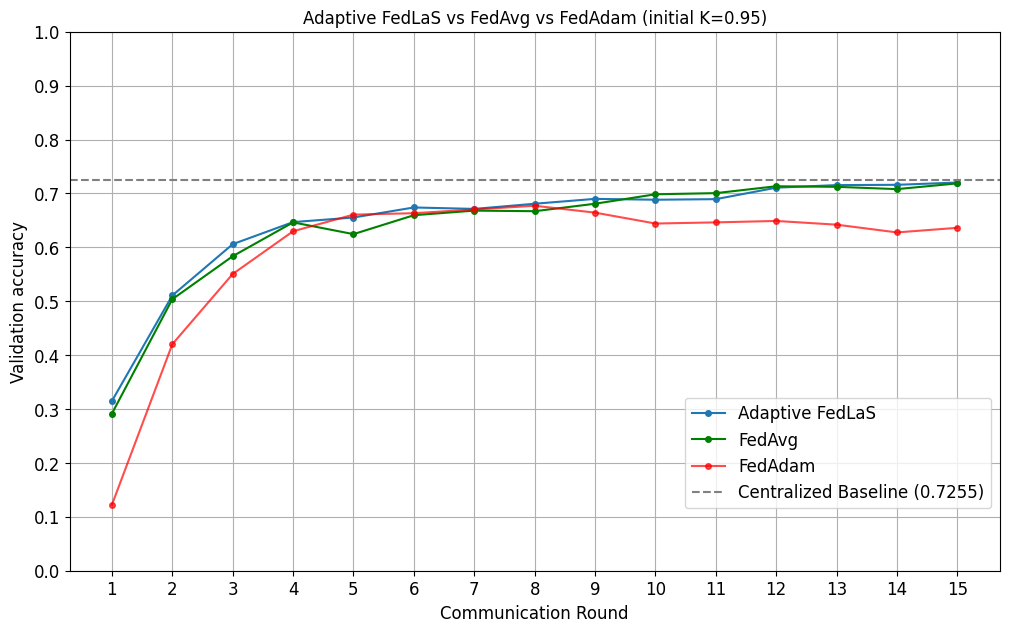

In [117]:
import matplotlib.pyplot as plt

x_values = range(1, ROUNDS+2)

plt.figure(figsize=(12, 7))
plt.plot(x_values, stitched_accuracy, label='Adaptive FedLaS', marker='o', markersize=4)
plt.plot(x_values, fedavg_accuracy, label='FedAvg', color='green', marker='o', markersize=4)
plt.plot(x_values, fedadam_accuracy, label='FedAdam', color='red', alpha=0.7, marker='o', markersize=4)

# Add the baseline validation accuracy as a fixed dashed line
plt.axhline(y=baseline_acc, color='gray', linestyle='--', label=f'Centralized Baseline ({baseline_acc:.4f})')

plt.xlabel('Communication Round', fontsize='large')
plt.ylabel('Validation accuracy', fontsize='large')
plt.title('Adaptive FedLaS vs FedAvg vs FedAdam (initial K=0.95)')

# Set x-axis ticks to integers
plt.xticks(x_values)

# Set y-axis ticks with increments of 0.1
plt.yticks([i / 10 for i in range(11)])
plt.tick_params(axis='both', labelsize='large')  # Increase tick font size

plt.ylim(0, 1)  # Set Y-axis limits from 0 to 1

# Move legend lower
plt.legend(loc='lower right', bbox_to_anchor=(1, 0.1), fontsize='large')
plt.grid(True)

# Save the plot as a vector image
plt.savefig(f'comparison_{DATASET}_{SEED}.eps', format='eps')

plt.show()

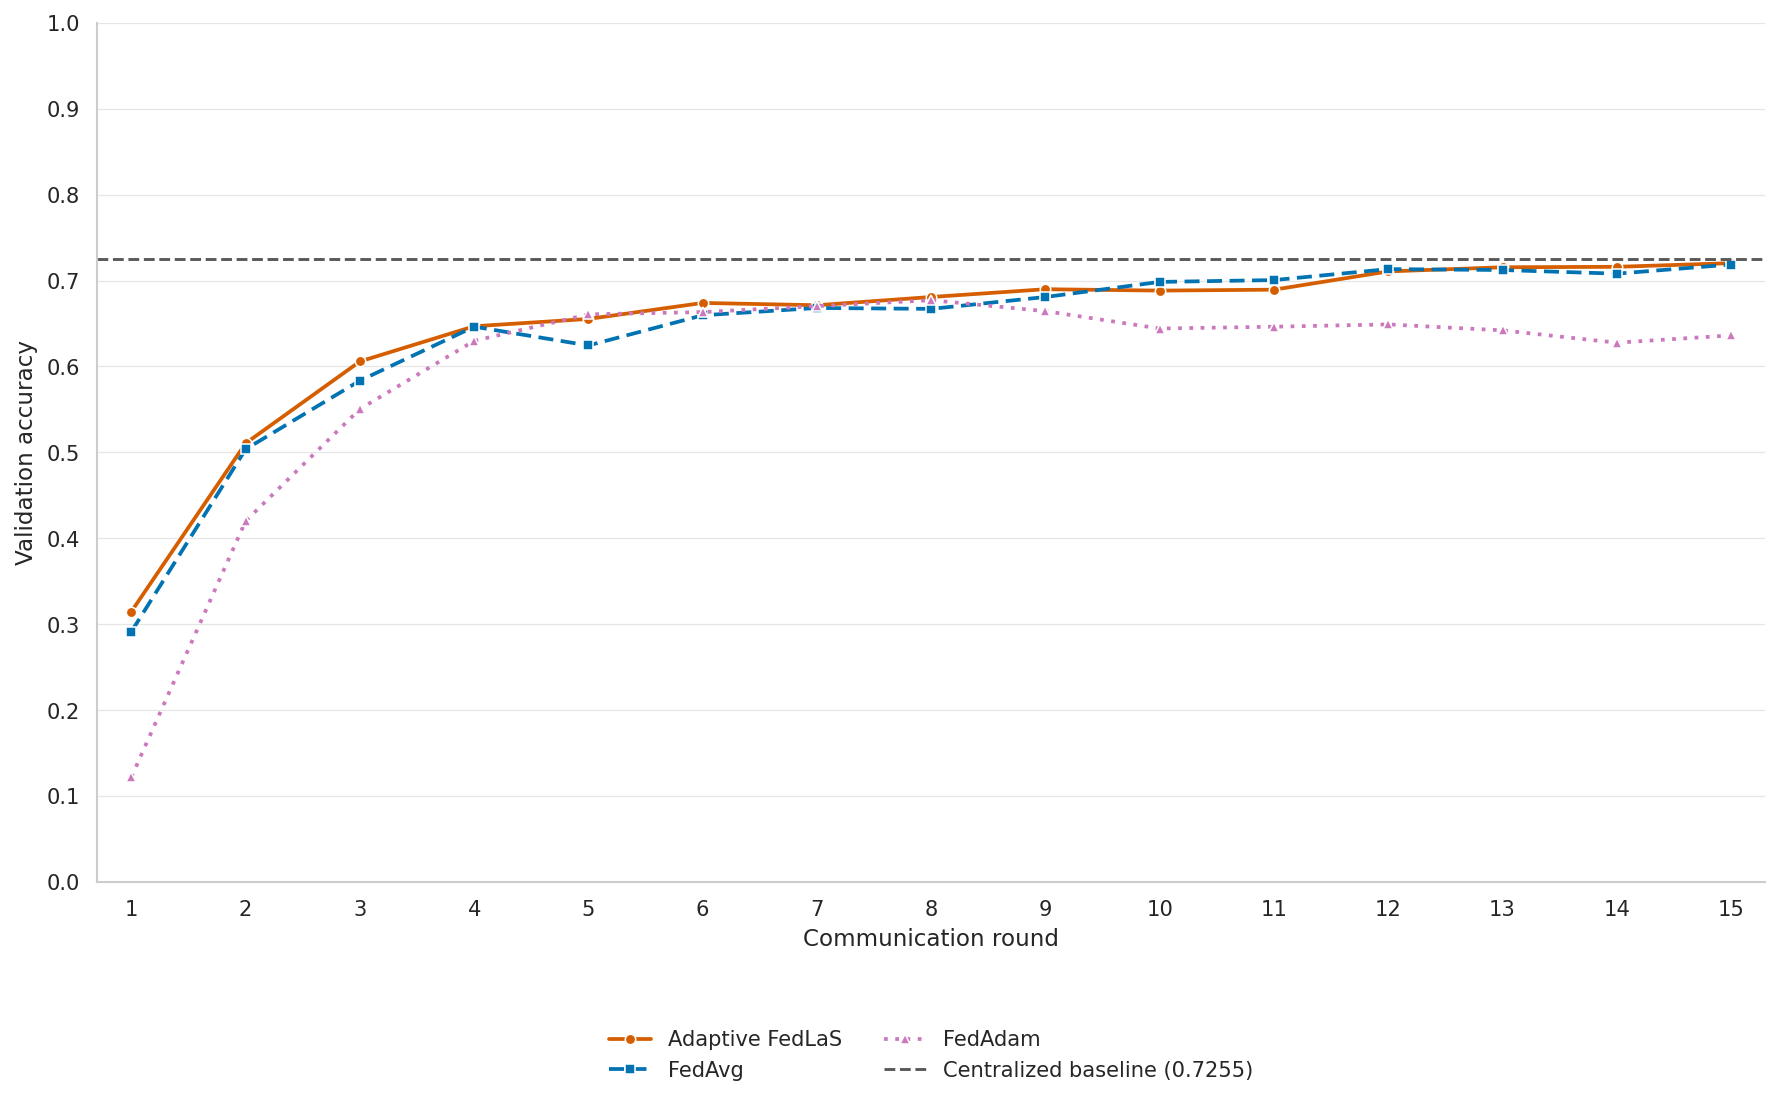

In [118]:
# Seaborn alternative for a paper figure
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

seaborn_methods = ["Adaptive FedLaS", "FedAvg", "FedAdam"]
seaborn_rounds = range(1, len(stitched_accuracy) + 1)
seaborn_plot_data = pd.DataFrame({
    "Round": seaborn_rounds,
    "Adaptive FedLaS": stitched_accuracy,
    "FedAvg": fedavg_accuracy,
    "FedAdam": fedadam_accuracy,
}).melt(id_vars="Round", var_name="Method", value_name="Accuracy")

seaborn_colors = sns.color_palette("colorblind")
seaborn_palette = dict(zip(seaborn_methods, [seaborn_colors[3], seaborn_colors[0], seaborn_colors[4]]))

with (
    sns.axes_style("whitegrid"),
    sns.plotting_context("paper", font_scale=1.15),
    plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42}),
):
    # Figure width and height for better visibility of rounds and accuracy values.
    seaborn_fig, seaborn_ax = plt.subplots(figsize=(12, 7.5), dpi=150)
    sns.lineplot(
        data=seaborn_plot_data, x="Round", y="Accuracy",
        hue="Method", style="Method",
        hue_order=seaborn_methods, style_order=seaborn_methods,
        palette=seaborn_palette,
        markers={"Adaptive FedLaS": "o", "FedAvg": "s", "FedAdam": "^"},
        dashes={"Adaptive FedLaS": "", "FedAvg": (4, 2), "FedAdam": (1, 2)},
        linewidth=1.8, markersize=5,
        estimator=None, errorbar=None, ax=seaborn_ax,
    )
    seaborn_ax.axhline(
        baseline_acc, color="0.35", linestyle="--", linewidth=1.4,
        label=f"Centralized baseline ({baseline_acc:.4f})",
    )
    seaborn_ax.set(
        xlabel="Communication round", ylabel="Validation accuracy",
        xlim=(0.7, len(stitched_accuracy) + 0.3), ylim=(0, 1),
        xticks=list(seaborn_rounds),
    )
    # Display fractional decimal values (0.0, 0.1, 0.2, etc.)
    seaborn_ax.set_yticks([i / 10 for i in range(11)])

    seaborn_ax.grid(axis="x", visible=False)
    seaborn_ax.grid(axis="y", color="0.9", linewidth=0.6)
    sns.despine(ax=seaborn_ax)
    seaborn_ax.legend(
        title=None, loc="upper center", bbox_to_anchor=(0.5, -0.15),
        ncol=2, frameon=False,
    )
    # Report the dataset and hyperparameters in the paper caption.
    seaborn_fig.tight_layout()
    seaborn_stem = f"comparison_{DATASET.lower()}__{SEED}"
    for seaborn_format in ("eps",):
        seaborn_fig.savefig(f"{seaborn_stem}.{seaborn_format}", bbox_inches="tight", facecolor="white")
    seaborn_fig.savefig(f"{seaborn_stem}.png", dpi=600, bbox_inches="tight", facecolor="white")
    plt.show()

#### 9a. Validation results across seeds

Run the training path from a fresh runtime for each `SEED` in `(42, 43, 44, 45, 46)`, with `LOAD_CHECKPOINTS=False`.

The next cell saves one result file per seed and computes each method's mean and **sample standard deviation** (`ddof=1`) at each round once all five runs are available.  
Repeating a seed replaces its file; it does not add another independent run.  
Sequential and parallel results are stored separately.

Keep the algorithm and settings fixed across runs; use a new results directory or regenerate all five files when changing them.

The new plot shows the mean with a shaded **±1 SD** band (not a confidence interval). The centralized baseline's final validation accuracy is a constant reference within each seed, with its own mean and SD across seeds. Existing plots above remain single-run plots.


In [119]:
import json
import pandas as pd

EXPERIMENT_SEEDS = (42, 43, 44, 45, 46)
if LOAD_CHECKPOINTS or SEED not in EXPERIMENT_SEEDS:
    raise ValueError("Collect seed results with fresh training and a SEED from EXPERIMENT_SEEDS.")

validation_histories = {
    "Adaptive FedLaS": stitched_accuracy,
    "FedAvg": fedavg_accuracy,
    "FedAdam": fedadam_accuracy,
    "Centralized baseline": [baseline_acc] * (ROUNDS + 1),
}
if any(len(history) != ROUNDS + 1 for history in validation_histories.values()):
    raise ValueError("Complete all communication rounds before saving seed results.")

# Create results directory
seed_results_dir = ROOT_PATH / "results" / "fl_las_main" / DATASET
seed_results_dir.mkdir(parents=True, exist_ok=True)

# Config
run_config = {
    "dataset": DATASET, "backbone": BACKBONE_NAME,
    "num_clients": NUM_CLIENTS, "alpha": ALPHA, "batch_size": BATCH_SIZE,
    "rounds": ROUNDS + 1, "central_epochs": CENTRAL_EPOCHS,
    "split_sizes": [len(train_ds), len(val_ds), len(test_ds)],
    "dtd_partition": 1 if DATASET == "DTD" else None,
    "preprocess": str(preprocess),
    "fedadam": [FEDADAM_LR, FEDADAM_BETA1, FEDADAM_BETA2, FEDADAM_TAU],
}
validation_run = pd.DataFrame({
    "Round": range(1, ROUNDS + 2), **validation_histories,
}).melt(id_vars="Round", var_name="Method", value_name="Accuracy").assign(Seed=SEED)

# Save the whole notebook run results
(seed_results_dir / f"seed_{SEED}.json").write_text(json.dumps(
    {"config": run_config, "results": validation_run.to_dict(orient="records")},
    indent=2, allow_nan=False,
))

7643

In [120]:
validation_summary = pd.DataFrame()  # Clear any summary left from an earlier execution.
missing_seeds = [seed for seed in EXPERIMENT_SEEDS
                 if not (seed_results_dir / f"seed_{seed}.json").exists()]

if missing_seeds:
    print(f"Saved seed {SEED}. Still needed for mean ± SD: {missing_seeds}")
else:
    seed_frames = []
    for seed in EXPERIMENT_SEEDS:
        saved_run = json.loads((seed_results_dir / f"seed_{seed}.json").read_text())
        if saved_run["config"] != run_config:
            raise ValueError(f"Seed {seed} has different settings; regenerate it or use a new results directory.")
        frame = pd.DataFrame(saved_run["results"])
        if not frame["Seed"].eq(seed).all():
            raise ValueError(f"Seed label mismatch in seed_{seed}.json.")
        seed_frames.append(frame)

    validation_runs = pd.concat(seed_frames, ignore_index=True)
    if validation_runs.duplicated(["Seed", "Method", "Round"]).any():
        raise ValueError("Each method/round must have exactly one result per seed.")

    validation_summary = validation_runs.groupby(["Method", "Round"], sort=False)["Accuracy"].agg(
        Mean="mean", Std=lambda values: values.std(ddof=1), Seeds="count",
    ).reset_index()

    if not validation_summary["Seeds"].eq(len(EXPERIMENT_SEEDS)).all():
        validation_summary = pd.DataFrame()
        raise ValueError("Every method/round must include all experiment seeds.")

    validation_summary.to_csv(seed_results_dir / "validation_mean_std.csv", index=False)
    display(validation_summary)

,Method,Round,Mean,Std,Seeds
0,Adaptive FedLaS,1,0.310745,0.026391,5
1,Adaptive FedLaS,2,0.512872,0.024237,5
2,Adaptive FedLaS,3,0.600745,0.011021,5
3,Adaptive FedLaS,4,0.633723,0.023908,5
4,Adaptive FedLaS,5,0.651915,0.011400,5
5,Adaptive FedLaS,6,0.672340,0.009373,5
6,Adaptive FedLaS,7,0.668511,0.009414,5
7,Adaptive FedLaS,8,0.680000,0.009453,5
8,Adaptive FedLaS,9,0.684043,0.009851,5
9,Adaptive FedLaS,10,0.689894,0.008154,5


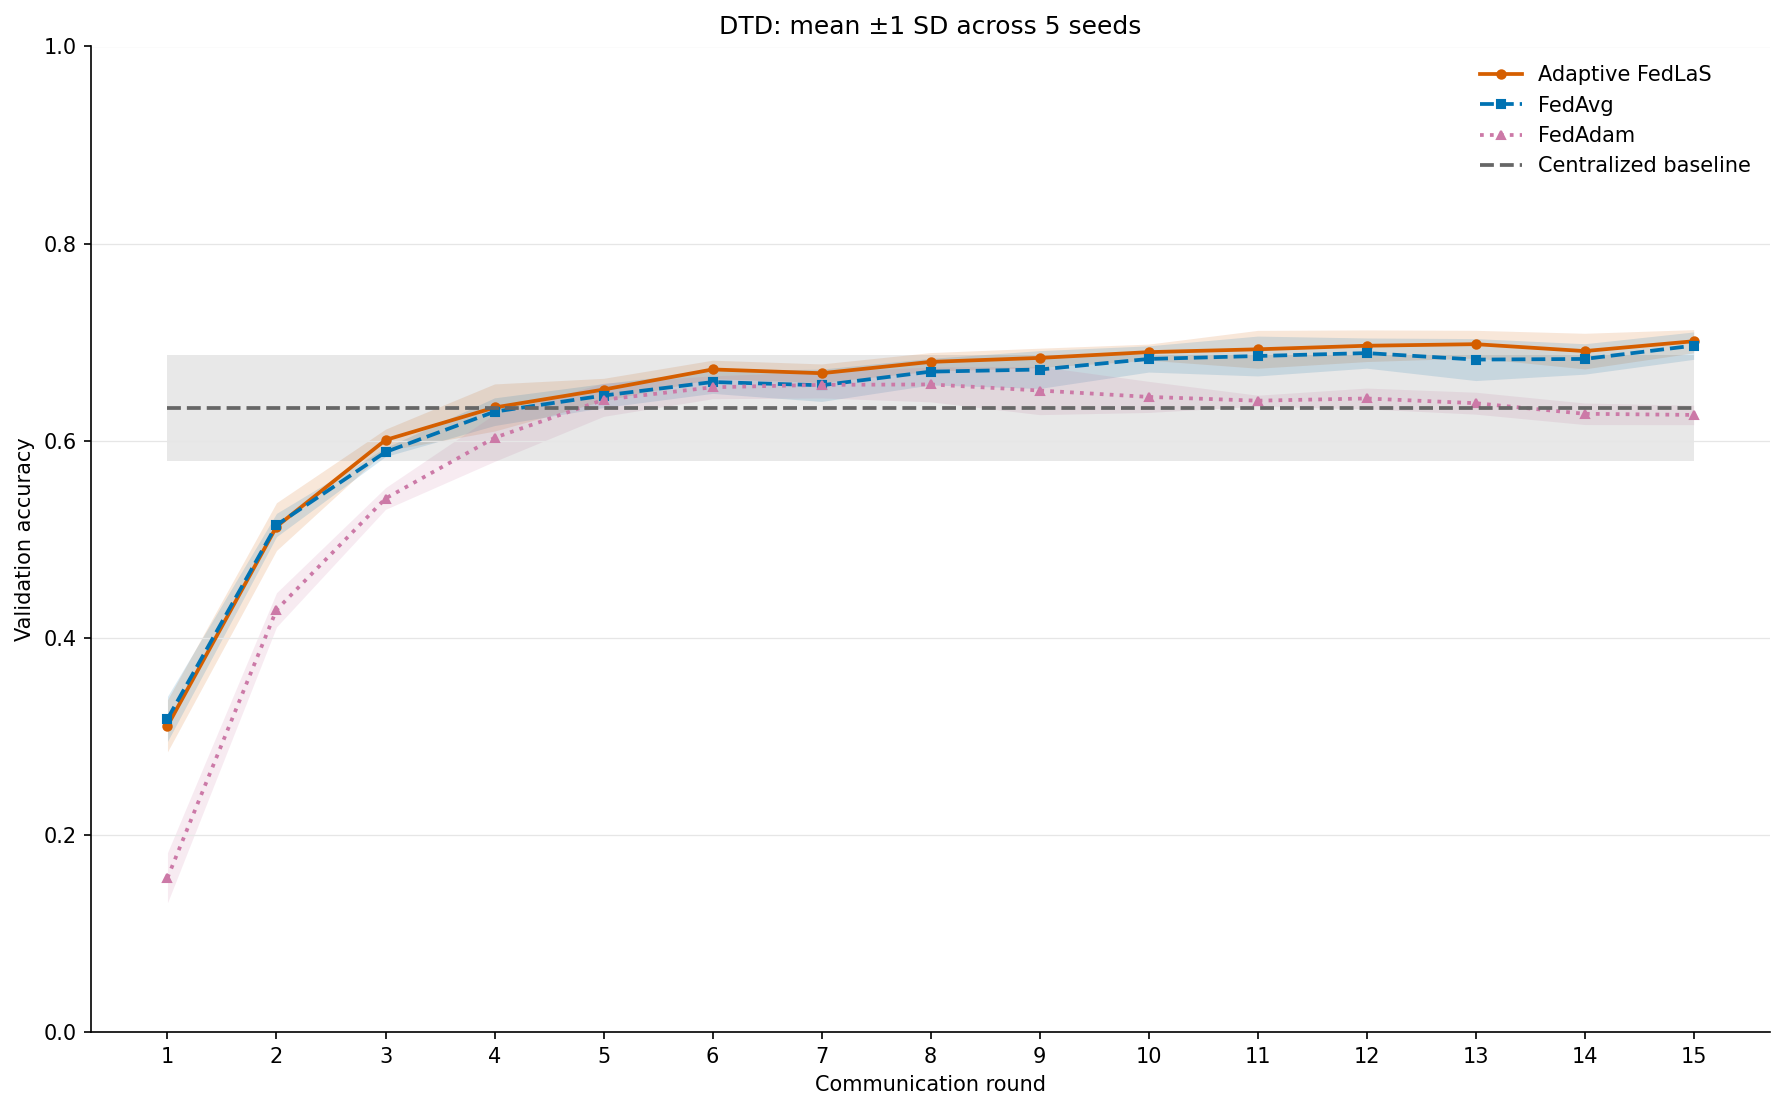

In [125]:
import matplotlib.pyplot as plt

if validation_summary.empty:
    print("Run all experiment seeds before plotting mean ± SD.")
else:
    seed_fig, seed_ax = plt.subplots(figsize=(12, 7.5), dpi=150)
    for method, color, marker, linestyle in [
        ("Adaptive FedLaS", "#D55E00", "o", "-"),
        ("FedAvg", "#0072B2", "s", "--"),
        ("FedAdam", "#CC79A7", "^", ":"),
        ("Centralized baseline", "0.4", None, "--"),
    ]:
        stats = validation_summary[validation_summary["Method"] == method].sort_values("Round")
        rounds = stats["Round"].to_numpy()
        mean = stats["Mean"].to_numpy()
        std = stats["Std"].to_numpy()
        seed_ax.plot(rounds, mean, label=method, color=color, marker=marker,
                     linestyle=linestyle, linewidth=1.8, markersize=4)
        seed_ax.fill_between(rounds, mean - std, mean + std, color=color, alpha=0.15, linewidth=0)
    seed_ax.set(xlabel="Communication round", ylabel="Validation accuracy",
                xticks=range(1, ROUNDS + 2), ylim=(0, 1),
                title=f"{DATASET}: mean ±1 SD across {len(EXPERIMENT_SEEDS)} seeds")
    seed_ax.grid(axis="y", color="0.9", linewidth=0.6)
    seed_ax.spines[["top", "right"]].set_visible(False)
    seed_ax.legend(frameon=False)
    seed_fig.tight_layout()
    seed_fig.savefig(seed_results_dir / "validation_mean_std.pdf", bbox_inches="tight")
    seed_fig.savefig(seed_results_dir / "validation_mean_std.png", dpi=600, bbox_inches="tight")
    plt.show()


### 10. Final test evaluation

Report test accuracy after all communication rounds. These scores do **not** control the retention schedule of $K$:

$$
K_t = 1 - \mu \times \text{validation accuracy}_{t-1}
$$

The test scores never enter this formula or affect training decisions, so the test set is an independent evaluation.

In [122]:
final_test_accuracy = {
    "Adaptive FedLaS": accuracy(stitched_model, test_loader),
    "FedAvg": accuracy(fedavg_model, test_loader),
    "FedAdam": accuracy(fedadam_model, test_loader),
    "Centralized baseline": accuracy(baseline_model, test_loader),
}
final_test_accuracy

{'Adaptive FedLaS': np.float64(0.7191489361702128),
 'FedAvg': np.float64(0.7138297872340426),
 'FedAdam': np.float64(0.6436170212765957),
 'Centralized baseline': np.float64(0.7329787234042553)}

#### 10a. Save test results and export a paper table

After evaluating the final models, run the next cells for each experiment seed. Test results are saved separately under `seed_results_dir / "test"`; rerunning a seed replaces its file.

For the paper, report **final test accuracy (%) as mean ± sample SD across all five seeds**. The table is exported as CSV (numeric statistics) and LaTeX (formatted mean ± SD). It appears only after all five test-result files have matching settings. The saved accuracies remain fractions in `[0, 1]`; percentage conversion is only for reporting.


In [123]:
import json
import pandas as pd

if LOAD_CHECKPOINTS or SEED not in EXPERIMENT_SEEDS:
    raise ValueError("Save test results from fresh training with an experiment seed.")
if any(len(history) != ROUNDS + 1 for history in validation_histories.values()):
    raise ValueError("Complete all communication rounds before saving final test results.")
if set(final_test_accuracy) != set(validation_histories):
    raise ValueError("Test results must include the same methods as the validation experiment.")

test_run = pd.DataFrame([
    {"Seed": SEED, "Method": method, "Accuracy": float(value)}
    for method, value in final_test_accuracy.items()
])
if not test_run["Accuracy"].between(0, 1).all():
    raise ValueError("Test accuracies must be finite fractions in [0, 1].")

test_results_dir = seed_results_dir / "test"
test_results_dir.mkdir(parents=True, exist_ok=True)
test_result_path = test_results_dir / f"seed_{SEED}.json"
test_result_path.write_text(json.dumps(
    {"split": "test", "config": run_config, "results": test_run.to_dict(orient="records")},
    indent=2, allow_nan=False,
))
print(f"Saved final test accuracies for seed {SEED}: {test_result_path}")


Saved final test accuracies for seed 46: /content/drive/.shortcut-targets-by-id/1lkGWDaEqwUq5POJx7d0cB9z1ZKZTjgKK/Graduation Thesis/fl_localize_stitch_vit/results/fl_las_main/DTD/test/seed_46.json


In [ ]:
test_summary = pd.DataFrame()
paper_test_table = pd.DataFrame()
missing_test_seeds = [seed for seed in EXPERIMENT_SEEDS
                      if not (test_results_dir / f"seed_{seed}.json").exists()]

if missing_test_seeds:
    print(f"Test results still needed for mean ± SD: {missing_test_seeds}")
else:
    test_frames = []
    for seed in EXPERIMENT_SEEDS:
        saved_test_run = json.loads((test_results_dir / f"seed_{seed}.json").read_text())
        if saved_test_run.get("split") != "test" or saved_test_run["config"] != run_config:
            raise ValueError(f"Seed {seed} has a different split or settings; regenerate its test results.")
        test_frame = pd.DataFrame(saved_test_run["results"])
        if (not test_frame["Seed"].eq(seed).all()
                or set(test_frame["Method"]) != set(final_test_accuracy)
                or test_frame["Method"].duplicated().any()
                or not test_frame["Accuracy"].between(0, 1).all()):
            raise ValueError(f"Invalid or incomplete test results in seed_{seed}.json.")
        test_frames.append(test_frame)

    test_runs = pd.concat(test_frames, ignore_index=True)
    test_summary = test_runs.groupby("Method", sort=False)["Accuracy"].agg(
        Mean="mean", Std=lambda values: values.std(ddof=1), Seeds="count",
    ).reset_index()
    if not test_summary["Seeds"].eq(len(EXPERIMENT_SEEDS)).all():
        test_summary = pd.DataFrame()
        raise ValueError("Every method must include exactly one test result per experiment seed.")

    test_summary = test_summary.rename(columns={"Mean": "Mean (%)", "Std": "SD (pp)"})
    test_summary[["Mean (%)", "SD (pp)"]] *= 100
    test_summary.to_csv(test_results_dir / "test_accuracy_mean_std.csv", index=False)
    paper_test_table = pd.DataFrame({
        "Method": test_summary["Method"],
        "Test accuracy (%)": [f"{mean:.2f} ± {std:.2f}"
                              for mean, std in zip(test_summary["Mean (%)"], test_summary["SD (pp)"])],
    })
    display(paper_test_table)


,Method,Test accuracy (%)
0,Adaptive FedLaS,71.52 ± 0.79
1,FedAvg,70.80 ± 0.90
2,FedAdam,64.27 ± 0.81
3,Centralized baseline,63.84 ± 5.73
